In [ ]:
!pip install mne -q

import mne

fname = "/content/L_07_SE001_CB_Train03.edf"

raw = mne.io.read_raw_edf(
    fname,
    preload=True
)

print(raw)

print("\n==============================")
print("CHANNELS")
print("==============================")
print(raw.ch_names)

print("\n==============================")
print("SAMPLING RATE")
print("==============================")
print(raw.info['sfreq'])

print("\n==============================")
print("ANNOTATIONS")
print("==============================")
print(raw.annotations)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 87.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Extracting EDF parameters from /content/L_07_SE001_CB_Train03.edf...
Setting channel info structure...
Creating raw.info structure...


/tmp/ipykernel_1316/816051327.py:7: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(
/tmp/ipykernel_1316/816051327.py:7: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(


Reading 0 ... 55815  =      0.000 ...   218.027 secs...
<RawEDF | L_07_SE001_CB_Train03.edf, 62 x 55816 (218.0 s), ~26.5 MiB, data loaded>

CHANNELS
['EEG_F3', 'EEG_Fz', 'EEG_F4', 'EEG_T7', 'EEG_C3', 'EEG_Cz', 'EEG_C4', 'EEG_T8', 'EEG_CP3', 'EEG_CP4', 'EEG_P3', 'EEG_Pz', 'EEG_P4', 'EEG_PO7', 'EEG_PO8', 'EEG_Oz', 'A_1_1', 'B_1_2', 'C_1_3', 'D_1_4', 'E_1_5', 'F_1_6', 'G_2_1', 'H_2_2', 'I_2_3', 'J_2_4', 'K_2_5', 'L_2_6', 'M_3_1', 'N_3_2', 'O_3_3', 'P_3_4', 'Q_3_5', 'R_3_6', 'S_4_1', 'T_4_2', 'U_4_3', 'V_4_4', 'W_4_5', 'X_4_6', 'Y_5_1', 'Z_5_2', 'Sp_5_3', '1_5_4', '2_5_5', '3_5_6', '4_6_1', '5_6_2', '6_6_3', '7_6_4', '8_6_5', '9_6_6', 'StimulusType', 'SelectedTarget', 'SelectedRow', 'SelectedColumn', 'PhaseInSequence', 'StimulusBegin', 'StimulusCode', 'CurrentTarget', 'FakeFeedback', 'DisplayResults']

SAMPLING RATE
256.00005870719417

ANNOTATIONS
<Annotations | 1 segment: Begin recording (1)>


In [ ]:
print(raw.get_data(picks=["StimulusCode"]).shape)

stim = raw.get_data(picks=["StimulusCode"])[0]

print("\nUnique Stimulus Codes:")
print(set(stim))

(1, 55816)

Unique Stimulus Codes:
{np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0), np.float64(52.0), np.float64(53.0), np

In [ ]:
import numpy as np
import mne

# ── Extract stimulus channel ─────────────────────────
stim = raw.get_data(picks=["StimulusCode"])[0]

# Convert to integer
stim = stim.astype(int)

# ── Find changes in stimulus ─────────────────────────
changes = np.where(np.diff(stim) > 0)[0]

events = []

for idx in changes:
    code = stim[idx + 1]

    # Skip zeros
    if code != 0:
        events.append([idx, 0, code])

events = np.array(events)

print("Events shape:")
print(events.shape)

print("\nFirst 20 events:")
print(events[:20])

Events shape:
(756, 3)

First 20 events:
[[1159    0   93]
 [1223    0   92]
 [1287    0   94]
 [1351    0   91]
 [1415    0   95]
 [1479    0   99]
 [1543    0   98]
 [1607    0   96]
 [1671    0  100]
 [1735    0   97]
 [1799    0  101]
 [1863    0  102]
 [1927    0  104]
 [1991    0  103]
 [2055    0  107]
 [2119    0  105]
 [2183    0  108]
 [2247    0  106]
 [2311    0   57]
 [2375    0   58]]


In [ ]:
# ── Select ear-adjacent channels ─────────────────────
ear_channels = [
    "EEG_T7",
    "EEG_T8",
    "EEG_PO7",
    "EEG_PO8"
]

raw_ear = raw.copy().pick(ear_channels)

print("Using channels:")
print(raw_ear.ch_names)

# ── Basic filtering ──────────────────────────────────
raw_ear.filter(
    l_freq=0.1,
    h_freq=15,
    verbose=False
)

# ── Create epochs around flashes ────────────────────
epochs = mne.Epochs(
    raw_ear,
    events,
    tmin=-0.2,
    tmax=0.8,
    baseline=(None, 0),
    preload=True,
    verbose=False
)

print("\nEpoch shape:")
print(epochs.get_data().shape)

print("\nEpoch duration:")
print(f"{epochs.tmin} to {epochs.tmax} sec")

Using channels:
['EEG_T7', 'EEG_T8', 'EEG_PO7', 'EEG_PO8']

Epoch shape:
(756, 4, 257)

Epoch duration:
-0.19921870431417518 to 0.8007810663609002 sec


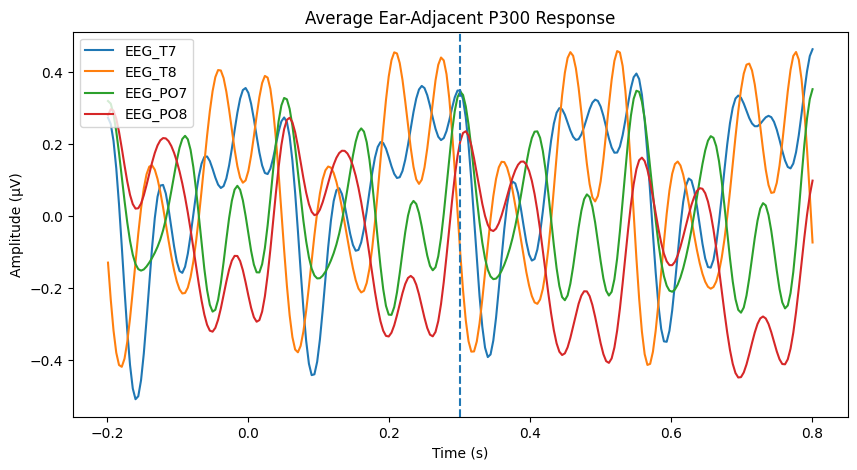

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get epoch data
data = epochs.get_data()

# Average all epochs
avg = data.mean(axis=0)

# Time axis
times = epochs.times

# Plot
plt.figure(figsize=(10,5))

for i, ch in enumerate(epochs.ch_names):
    plt.plot(
        times,
        avg[i] * 1e6,
        label=ch
    )

plt.axvline(
    x=0.3,
    linestyle='--'
)

plt.xlabel("Time (s)")
plt.ylabel("Amplitude (µV)")
plt.title("Average Ear-Adjacent P300 Response")

plt.legend()

plt.show()